# Phase 5: Population dynamics

Phases 2–4 asked *how well* the 142 neurons predict the hand. This phase asks *how the population is organized*: what shape its activity takes, how many dimensions it really uses, and when it changes relative to the movement.

**Five questions**
1. **Dimensionality:** 142 neurons give 142 numbers per time point, but how many independent patterns (dimensions) does the population actually use?
2. **Neural trajectories:** what path does the population state trace during reaches in different directions?
3. **Timing:** when does the population start changing, relative to when the hand starts moving?
4. **Decoding from a few dimensions:** how much of the decoding accuracy survives if the decoder sees only the top few dimensions?
5. **Rotational dynamics (jPCA):** during the reach, does the population state rotate, as reported in classic work on this kind of data ([Churchland et al., 2012](https://www.nature.com/articles/nature11129))?

**Key tool: PCA (principal component analysis).** PCA finds the directions in the 142-neuron space along which activity varies most. Each direction, a *principal component* or PC, is a weighted mix of neurons. Projecting onto the top few PCs gives a compact picture of what the whole population is doing.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

sys.path.insert(0, os.path.abspath(".."))
from src.data import BIN_MS, load_dataset, get_trials, build_features
from src.decoders import fit_ridge
from src.dynamics import reach_angles, direction_labels, condition_average, soft_normalize, pca, fit_jpca

DATA_PATH = "../data/000140/sub-Jenkins/"
WINDOW = (-400, 500)          # ms around movement onset: includes planning before the reach
SMOOTH_MS = 20                # Gaussian smoothing (standard deviation) for average firing rates
N_TRAJ_PCS = 10               # dimensions used to measure how fast the population state changes
K_LIST = [1, 2, 5, 10, 20, 40]   # numbers of dimensions to give the decoder
RIDGE_ALL_NEURONS = 0.606     # Phase 3: ridge with all 142 neurons, 400 ms history, same test bins
JPCA_WINDOW = (-60, 200)      # ms around movement onset for the rotation analysis
os.makedirs("../figures", exist_ok=True)

## 1. Load, smooth, and average by reach direction

Single trials are noisy, so dynamics are usually studied on **condition averages**: each neuron's firing rate averaged over all trials of the same type. Here a condition is a reach-direction bin (45° wide), as in Phase 1, keeping bins with at least 5 trials. Spikes are smoothed with a 20 ms Gaussian kernel. The smoothing is centered in time, which is fine for describing activity but not something a real-time decoder could use.

**Soft normalization:** each neuron is divided by its range of average rates plus 5 Hz. Without it, a few high-firing neurons would dominate PCA. The +5 Hz keeps nearly silent neurons from being inflated into noise.

In [2]:
dataset = load_dataset(DATA_PATH)
dataset.smooth_spk(SMOOTH_MS, name="smth")              # adds smoothed spikes as "spikes_smth"
trials = get_trials(dataset, history_ms=0, window=WINDOW)

angles = reach_angles(trials)
labels, centers = direction_labels(angles)
rates, conds, times = condition_average(trials, labels)  # conditions x times x neurons, in Hz
norm = soft_normalize(rates)
C, T, N = norm.shape
print(f"{C} reach-direction conditions: " + ", ".join(f"{centers[c]:.0f}°" for c in conds))
print(f"{T} time points ({times[0]} to {times[-1]} ms) x {N} neurons")
print("trials per condition:", pd.Series(labels).value_counts().sort_index().to_dict())

5 reach-direction conditions: -158°, -22°, 22°, 112°, 158°
45 time points (-400 to 480 ms) x 142 neurons
trials per condition: {0: 18, 3: 23, 4: 24, 6: 11, 7: 24}


## 2. Dimensionality: how many patterns does the population use?

PCA is run on the condition-averaged activity, with every condition and time point treated as one sample of the 142-neuron population. The plot shows how much of the total variance each PC captures. If a handful of PCs capture most of it, the population's activity is **low-dimensional**: the neurons move together in a few coordinated patterns instead of 142 independent ones.

PC1-PC3 capture 37% of the variance; 22 PCs capture 80% and 37 capture 90% (out of 142 neurons)


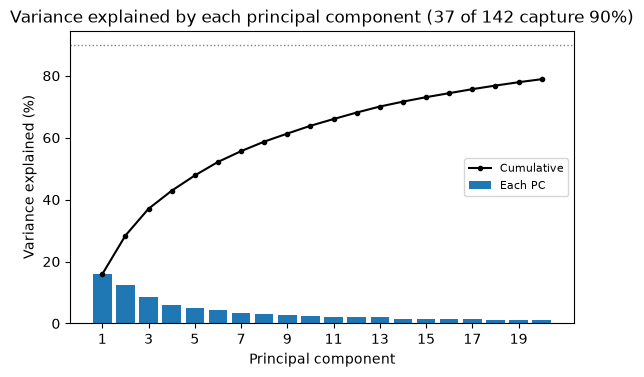

In [3]:
comps, ratio, mean = pca(norm.reshape(C * T, N))
cum = np.cumsum(ratio)
n80, n90 = int(np.searchsorted(cum, 0.80) + 1), int(np.searchsorted(cum, 0.90) + 1)
print(f"PC1-PC3 capture {cum[2]:.0%} of the variance; {n80} PCs capture 80% and {n90} capture 90% (out of {N} neurons)")

# Figure 15: variance explained by each principal component
k_show = 20
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(np.arange(1, k_show + 1), ratio[:k_show] * 100, color="tab:blue", label="Each PC")
ax.plot(np.arange(1, k_show + 1), cum[:k_show] * 100, "o-", color="black", ms=3, label="Cumulative")
ax.axhline(90, color="gray", ls=":", lw=1)
ax.set_xlabel("Principal component"); ax.set_ylabel("Variance explained (%)")
ax.set_title(f"Variance explained by each principal component ({n90} of {N} capture 90%)")
ax.set_xticks(range(1, k_show + 1, 2)); ax.legend(fontsize=8, loc="center right")
plt.savefig("../figures/15_variance_explained.png", dpi=150, bbox_inches="tight")

## 3. Neural trajectories

Each condition's activity, projected onto the top PCs, traces a path through "neural state space" over time: one line per reach direction. The open circle marks the start of the window (400 ms before movement onset), the filled dot marks movement onset, and the line ends 500 ms after.

**What to look for:** whether trajectories for different reach directions start close together and then separate, which would mean the population "commits" to a direction, and whether they separate *before* movement onset, which would point to preparatory activity.

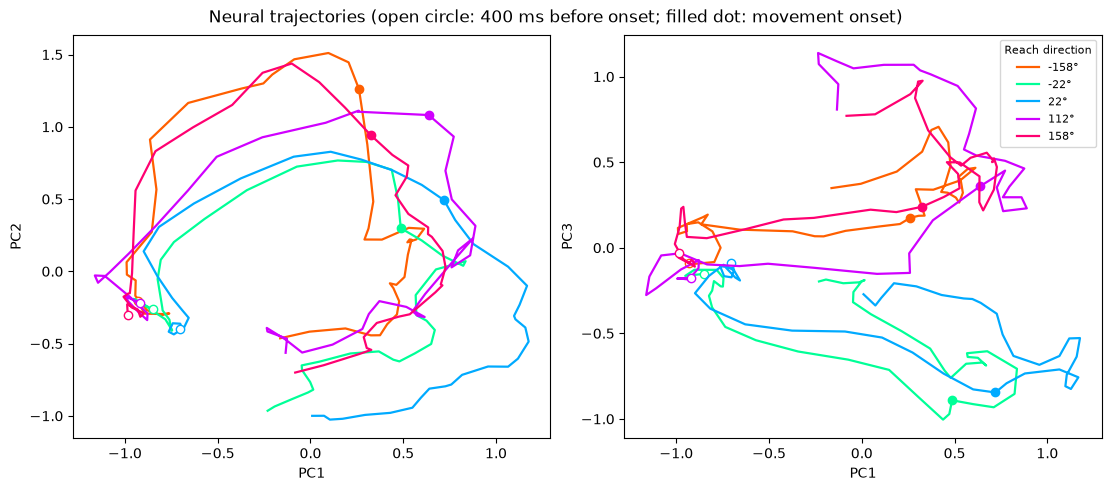

In [4]:
X = (norm.reshape(C * T, N) - mean) @ comps[:3].T
X = X.reshape(C, T, 3)
onset = int(np.argmin(np.abs(times)))
cmap = plt.cm.hsv

# Figure 16: neural trajectories in the top principal components, one line per reach direction
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), constrained_layout=True)
for ax, (a, b) in zip(axes, [(0, 1), (0, 2)]):
    for i, c in enumerate(conds):
        color = cmap((centers[c] + 180) / 360)
        ax.plot(X[i, :, a], X[i, :, b], color=color, lw=1.6, label=f"{centers[c]:.0f}°")
        ax.plot(X[i, 0, a], X[i, 0, b], "o", mfc="white", mec=color, ms=6)
        ax.plot(X[i, onset, a], X[i, onset, b], "o", color=color, ms=6)
    ax.set_xlabel(f"PC{a + 1}"); ax.set_ylabel(f"PC{b + 1}")
axes[1].legend(title="Reach direction", fontsize=8, title_fontsize=8, loc="best")
fig.suptitle("Neural trajectories (open circle: 400 ms before onset; filled dot: movement onset)")
plt.savefig("../figures/16_neural_trajectories.png", dpi=150, bbox_inches="tight")

## 4. Timing: when does the population change, relative to the hand?

**Neural speed** is how fast the population state moves through the top 10 PCs from one time bin to the next, averaged over conditions. **Hand speed** is the average speed of the hand. Both are scaled from 0 to 1 so their timing can be compared. The time each first reaches half its peak marks when it "takes off."

This connects to the decoders: the Kalman filter chose a 160 ms lag, and ridge improved with longer spike history. Both suggest the population changes well before the hand.

Neural speed reaches half its peak at -210 ms; hand speed at 60 ms -> population activity leads the hand by about 270 ms


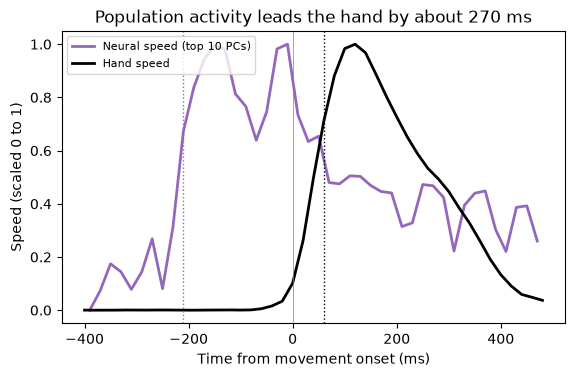

In [5]:
Xk = ((norm.reshape(C * T, N) - mean) @ comps[:N_TRAJ_PCS].T).reshape(C, T, N_TRAJ_PCS)
neural_speed = np.linalg.norm(np.diff(Xk, axis=1), axis=2).mean(axis=0) / (BIN_MS / 1000)
t_mid = (times[:-1] + times[1:]) / 2

t_all = (trials["align_time"].dt.total_seconds() * 1000).round().astype(int).to_numpy()
hand_speed = (pd.Series(np.linalg.norm(trials["hand_vel"][["x", "y"]].to_numpy(dtype=float), axis=1))
              .groupby(t_all).mean().reindex(times).to_numpy())

def scale01(v):
    return (v - np.nanmin(v)) / (np.nanmax(v) - np.nanmin(v))

def half_max_time(t, v):
    # first time the scaled curve reaches 0.5, on the rise to its peak
    s = scale01(v)
    peak = int(np.nanargmax(s))
    above = np.flatnonzero(s[:peak + 1] >= 0.5)
    return t[above[0]]

t_neural, t_hand = half_max_time(t_mid, neural_speed), half_max_time(times, hand_speed)
lead = t_hand - t_neural
lead_text = (f"population activity leads the hand by about {lead:.0f} ms" if lead > 0
             else f"population activity does not lead the hand ({lead:.0f} ms)")
print(f"Neural speed reaches half its peak at {t_neural:.0f} ms; hand speed at {t_hand:.0f} ms -> {lead_text}")

# Figure 17: population activity changes before the hand moves
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(t_mid, scale01(neural_speed), color="tab:purple", lw=2, label="Neural speed (top 10 PCs)")
ax.plot(times, scale01(hand_speed), color="black", lw=2, label="Hand speed")
for tt, color in [(t_neural, "tab:purple"), (t_hand, "black")]:
    ax.axvline(tt, color=color, ls=":", lw=1)
ax.axvline(0, color="gray", lw=0.5)
ax.set_xlabel("Time from movement onset (ms)"); ax.set_ylabel("Speed (scaled 0 to 1)")
ax.set_title(lead_text[0].upper() + lead_text[1:])
ax.legend(fontsize=8, loc="upper left")
plt.savefig("../figures/17_neural_vs_hand_speed.png", dpi=150, bbox_inches="tight")

## 5. How many dimensions does a decoder need?

If the population's activity is low-dimensional, a decoder may need only its top few dimensions. Here, the 400 ms ridge decoder from Phase 3 is refit using only the top *k* PCs of the spike counts instead of all 142 neurons.

To avoid leakage, the PCs are computed from **training trials only**, and the same 20 test trials and 700 bins are used as before. This cell takes a few minutes.

700 test bins
 dimensions  R² x   R² y  R² mean
          1 0.024 -0.031   -0.003
          2 0.204 -0.004    0.100
          5 0.452  0.303    0.378
         10 0.499  0.343    0.421
         20 0.583  0.403    0.493
         40 0.658  0.378    0.518
All 142 neurons (Phase 3): R² = 0.606


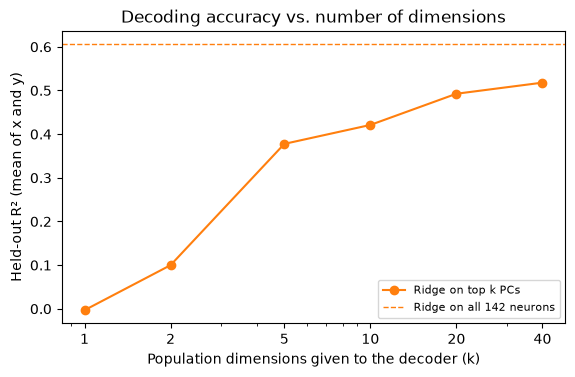

In [6]:
trials_dec = get_trials(dataset, history_ms=400)
X_all, y, groups, t_ms = build_features(trials_dec, n_lags=400 // BIN_MS)
n_neurons, n_blocks = trials_dec["spikes"].shape[1], 400 // BIN_MS + 1
trial_ids = np.unique(trials_dec["trial_id"])
test_ids = np.random.default_rng(0).choice(trial_ids, size=20, replace=False)   # same as every phase
train, test = ~np.isin(groups, test_ids), np.isin(groups, test_ids)

blocks = X_all.reshape(len(X_all), n_blocks, n_neurons)        # (bins, history step, neurons)
mu, sd = blocks[train, 0].mean(axis=0), blocks[train, 0].std(axis=0)
sd[sd == 0] = 1
spike_pcs, _, _ = pca((blocks[train, 0] - mu) / sd)            # PCs from training trials only

rows = []
for k in K_LIST:
    feats = (((blocks - mu) / sd) @ spike_pcs[:k].T).reshape(len(blocks), -1)
    search = fit_ridge(feats[train], y[train], groups[train])
    rx, ry = r2_score(y[test], search.predict(feats[test]), multioutput="raw_values")
    rows.append({"dimensions": k, "R² x": rx, "R² y": ry, "R² mean": (rx + ry) / 2})
dims = pd.DataFrame(rows)
print(f"{int(test.sum())} test bins")
print(dims.round(3).to_string(index=False))
print(f"All {n_neurons} neurons (Phase 3): R² = {RIDGE_ALL_NEURONS:.3f}")

# Figure 18: decoding accuracy vs. number of population dimensions
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(dims["dimensions"], dims["R² mean"], "o-", color="tab:orange", label="Ridge on top k PCs")
ax.axhline(RIDGE_ALL_NEURONS, color="tab:orange", ls="--", lw=1, label=f"Ridge on all {n_neurons} neurons")
ax.set_xscale("log"); ax.set_xticks(K_LIST); ax.set_xticklabels([str(k) for k in K_LIST])
ax.set_xlabel("Population dimensions given to the decoder (k)"); ax.set_ylabel("Held-out R² (mean of x and y)")
ax.set_title("Decoding accuracy vs. number of dimensions")
ax.legend(fontsize=8, loc="lower right")
plt.savefig("../figures/18_decoding_vs_dimensions.png", dpi=150, bbox_inches="tight")

## 6. Rotational dynamics (jPCA)

Churchland et al. (2012) reported that during reaching, motor-cortex population activity **rotates**: in a particular plane, the neural state circles around at a steady rate, like a pendulum. Their method, **jPCA**, searches the top 6 PCs for the plane where the state's motion is best described as a pure rotation.

The steps, from 60 ms before to 200 ms after movement onset:
1. Subtract the average across conditions at each time point, leaving only what differs between reach directions.
2. Reduce the result to its top 6 PCs.
3. Fit how the state changes from one bin to the next, twice: with **any linear dynamics**, and with **pure rotation**.
4. Plot the trajectories in the plane of strongest rotation.

**How to read it:** if the rotation-only fit explains most of what the unconstrained fit explains, the dynamics are largely rotational.

**Two caveats.** First, this dataset has only a few reach-direction conditions, far fewer than the original study, so the estimate is rough. Second, whether these rotations reflect a dynamical system or arise from other structure, such as neurons firing in sequence, has been debated ([Lebedev et al., 2019](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC6908571/)).

Top 6 PCs capture 68% of condition-specific variance; the jPC plane holds 27% of that
Fit of the state's change between bins: rotation only R² = 0.32, any linear dynamics R² = 0.38 (rotation captures 85% of it)
Rotation frequency: about 1.5 cycles per second


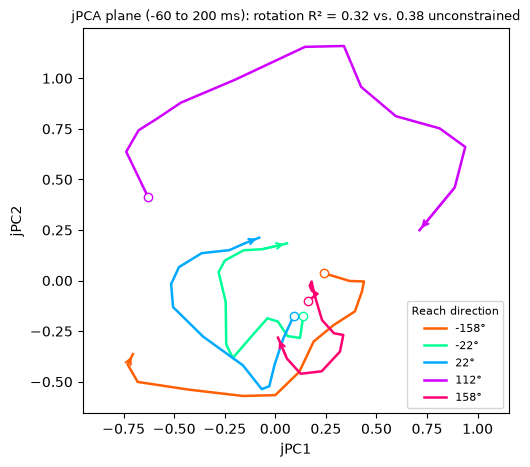

In [7]:
jp = fit_jpca(norm, times, JPCA_WINDOW)
print(f"Top 6 PCs capture {jp['pcs_variance']:.0%} of condition-specific variance; "
      f"the jPC plane holds {jp['plane_variance']:.0%} of that")
print(f"Fit of the state's change between bins: rotation only R² = {jp['r2_skew']:.2f}, "
      f"any linear dynamics R² = {jp['r2_best']:.2f} (rotation captures {jp['r2_skew'] / jp['r2_best']:.0%} of it)")
print(f"Rotation frequency: about {jp['freq_hz']:.1f} cycles per second")

# Figure 19: population activity in the plane of strongest rotation
fig, ax = plt.subplots(figsize=(5.5, 5))
for i, c in enumerate(conds):
    color = cmap((centers[c] + 180) / 360)
    p = jp["proj"][i]
    ax.plot(p[:, 0], p[:, 1], color=color, lw=1.8, label=f"{centers[c]:.0f}°")
    ax.plot(p[0, 0], p[0, 1], "o", mfc="white", mec=color, ms=6)
    ax.annotate("", xy=p[-1], xytext=p[-2], arrowprops=dict(arrowstyle="->", color=color, lw=1.5))
ax.set_xlabel("jPC1"); ax.set_ylabel("jPC2"); ax.set_aspect("equal", adjustable="datalim")
ax.set_title(f"jPCA plane ({JPCA_WINDOW[0]} to {JPCA_WINDOW[1]} ms): rotation R² = {jp['r2_skew']:.2f} "
             f"vs. {jp['r2_best']:.2f} unconstrained", fontsize=9)
ax.legend(title="Reach direction", fontsize=8, title_fontsize=8, loc="best")
plt.savefig("../figures/19_jpca_rotations.png", dpi=150, bbox_inches="tight")

## Results to record

Copy these lines into the README.

**How to read them together:**
- **Low dimensionality** (Figure 15) and **decoding from a few dimensions** (Figure 18) test the same idea from two sides. If a small number of PCs explain most of the activity and support most of the decoding accuracy, movement information lives on a low-dimensional "neural manifold."
- **Timing** (Figure 17) explains why the decoders needed long spike histories: the population changes before the hand does.
- **Trajectories and rotations** (Figures 16 and 19) describe how the population moves through that low-dimensional space during a reach.

**Reading the jPCA numbers:** the rotation is meaningful only if the jPC plane holds a substantial share of the condition-specific variance (roughly a quarter or more of the top-6-PC variance). If the plane holds only a few percent, the "rotation" sits in weak, noisy dimensions, and it's better to report that no clear rotational structure was found with this few conditions. That would be a legitimate result too.

**Caveat on timing:** the 20 ms smoothing kernel is centered, so it spreads activity slightly earlier and later in time. Treat the lead time as approximate, to within a few tens of milliseconds.

In [8]:
best = dims.loc[dims["R² mean"].idxmax()]
k10 = dims.loc[dims["dimensions"] == 10, "R² mean"].iloc[0]
print(f"Dimensionality: {n90} of {N} PCs capture 90% of condition-averaged variance (PC1-3: {cum[2]:.0%})")
print(f"Timing: {lead_text} (half-max comparison)")
print(f"Decoding: 10 PCs give R² = {k10:.2f} vs. {RIDGE_ALL_NEURONS:.2f} with all {N} neurons "
      f"(best: {best['R² mean']:.2f} with {int(best['dimensions'])} PCs)")
print(f"jPCA: rotation-only fit R² = {jp['r2_skew']:.2f} vs. {jp['r2_best']:.2f} unconstrained; "
      f"about {jp['freq_hz']:.1f} cycles per second; jPC plane holds {jp['plane_variance']:.0%} of top-6-PC variance")

Dimensionality: 37 of 142 PCs capture 90% of condition-averaged variance (PC1-3: 37%)
Timing: population activity leads the hand by about 270 ms (half-max comparison)
Decoding: 10 PCs give R² = 0.42 vs. 0.61 with all 142 neurons (best: 0.52 with 40 PCs)
jPCA: rotation-only fit R² = 0.32 vs. 0.38 unconstrained; about 1.5 cycles per second; jPC plane holds 27% of top-6-PC variance
